Import the modules that will be used.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

1. The corresponding values for each dimension in either vector is multiplied together. If each vector has n dimensions, then n multiplications
would have to be performed. Dot: O(n)
2. In a square matrix - vector multiplication, one dot product has to be performed for each row in the matrix, each involving n multiplications. The matrix has n rows, so n*n multiplications have to be performed, therefore n*n. O(n^2)
3. In a square matrix-matrix multiplication, a vector-matrix product has to be performed for each column in the second matrix. The second matrix has n columns, so nxnxn complexity. Therefore O(n^3) 

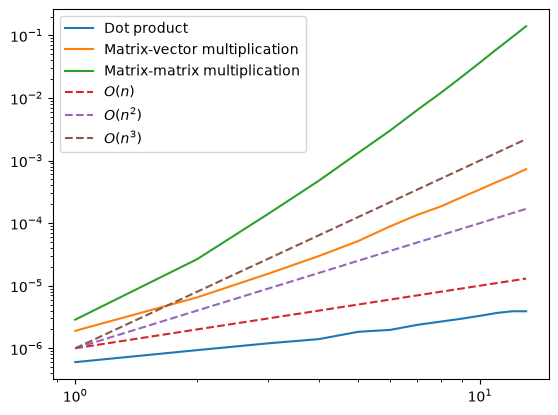

In [2]:
N = np.arange(1, 14)
dot_times = []
m_vtimes = []
m_mtimes = []

#compute dot product by doing n multiplications
def dot(x, y):
    z = []
    for i in range(len(x)):
        z.append(x[i] * y[i])
    return z

#compute matrix-vector multiplication by calling dot product n times
def m_v(x, y):
    z = []
    for i in range(len(x)):
        for j in x:
            z.append(dot(x[i], j))
    return z

#compute matric-matrix multiplication by calling matrix-vector product n times
def m_m(x, y):
    z = []
    for i in range(len(x)):
        row = []
        for j in range(len(y)):
            row.append(m_v(x, y[:, j]))
        z.append(row)
    return z
            
for n in N:
    V = np.random.rand(n)
    M = np.random.rand(n, n)
    
    t_1 = %timeit -n3 -q -o dot(V, V)
    dot_times.append(t_1.best)
    
    t_2 = %timeit -n3 -q -o m_v(M, V)
    m_vtimes.append(t_2.best)
    
    t_3 = %timeit -n3 -q -o m_m(M, M)
    m_mtimes.append(t_3.best)

plt.loglog(N, dot_times, label=r'Dot product')
plt.loglog(N, m_vtimes, label=r'Matrix-vector multiplication')
plt.loglog(N, m_mtimes, label=r'Matrix-matrix multiplication')
plt.loglog(N, 1e-6*N, '--', label=r'$O(n)$')
plt.loglog(N, 1e-6*N**2, '--', label=r'$O(n^2)$')
plt.loglog(N, 1e-6*N**3, '--', label=r'$O(n^3)$')

plt.legend()
plt.show()

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [3]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

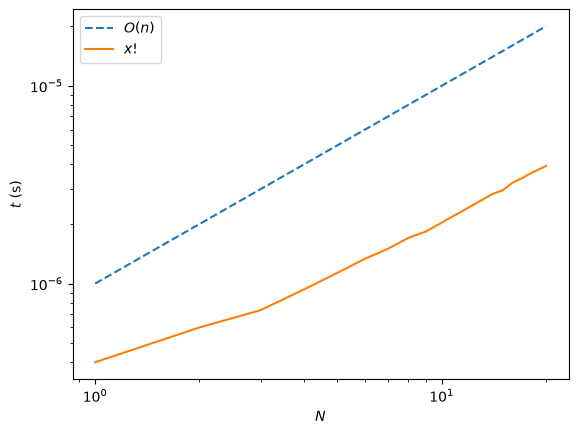

In [4]:
#i chose 21 beacuse it is the last number for which I will not gewt an overflow, whuich messes up the
#times for computing n!
N = np.arange(1, 21)
timesf = []

#compute factorial value of given numbers and store time taken
for n in N:
    t = %timeit -n3 -q -o factorial(n)
    timesf.append(t.best)

plt.loglog(N, (1e-6)*N, '--', label=r'$O(n)$')
plt.loglog(N, timesf, label=r'$x!$')

plt.xlabel('$N$')
plt.ylabel('$t$ (s)')

plt.legend()
plt.show()

#we can see computing the factorial of a number takes an amount of time that scales more or less linearly as n increases
#the x! line is roughly parallel to O(n), therefore we can say x! has a time complexity O(n)

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [5]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [6]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [7]:
# Create array of problem sizes we want to test (powers of 2)
#due to technical limitations, the largest matrix I coul compute was (2**13)x(2**13)
#past this value, the program would take an intractable amount of time to compute, as I checked.
N = 2**np.arange(2, 12)
times = []

def det(M):
    D = np.linalg.slogdet(M)
    return D
 
for i in N:
    B = np.random.rand(i, i)
    t = %timeit -n3 -q -o det(B)
    times.append(t.best)

Plot result:

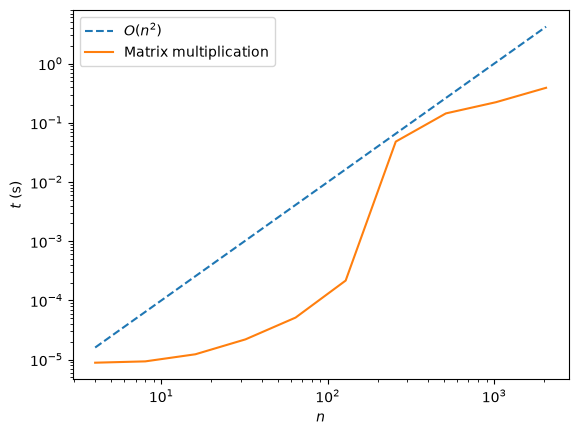

In [8]:
plt.loglog(N, 1e-6 * N**2, '--', label=r'$O(n^2$)')
plt.loglog(N, times, label="Matrix multiplication")

plt.legend()
plt.xlabel('$n$')
plt.ylabel('$t$ (s)')

plt.show()
#the curve for matrix multiplication somewhat resembles O(n^2). The complexity is definitely polynomial